# How Does Surface Deformation at an Active Volcano Relate to Pressure and Volume Change in the Magma Chamber?
<br>
This lesson has been adapted from an excel-based version within the 
SSAC Physical Volcanology Modules collection, available through SERC (https://serc.carleton.edu/sp/ssac/volcanology/volcmodules.html). The collection was 
developed by Chuck Connor (University of South Florida) and Peter LaFemina (Penn State). LaFemina
is the original author of this particular lesson on surface deformation.

## Learning Goals
1. Apply the Mogi (1958) point-source model to predict surface uplift and horizontal displacement.
2. Use Pearson's $\chi^2$ test to evaluate goodness of fit between model and data.
3. Solve for the best-fit magma-chamber depth and pressure or volume change.

## References & Resources
Amelung, F., Jonsson, S., Zebker, H., Segall, P., 2000. Widespread uplift and "trapdoor" faulting on Galapagos volcanoes observed with radar interferometry, Nature, 407, 993-996.

Delaney, P. and McTigue, 1994, Volume of magma accumulation or withdrawal estimated from surface uplift or subsidence, with application to the 1960 collapse of Kilauea volcano, Bull. Volc., 56, 417-424.

Johnson, D., Sigmundsson, F., and Delaney, P., 2000, Comment on "Volume of magma accumulation or withdrawal estimated from surface uplift or subsidence, with application to the 1960 collapse of Kilauea volcano," Bull. Volc., 61, 491-493.

Mogi, K., 1958. Relations between the eruptions of various volcanoes and the deformation of the ground surface around them, Bull. Earthquake Res. Inst., v. 36, 99-134.

**For a more sophisticated look at how surface deformation is calculated in modern research, check out dMODELS (available on VICTOR, https://pubs.usgs.gov/publication/tm13B3) and VMOD (https://github.com/uafgeotools/vmod).

## Background

### Mogi Point-Source Model

In 1958, Kiyoo Mogi from the Earthquake Research Institute, Japan, investigated the patterns of surface deformation associated with two historically active volcanoes, Sakurajima volcano, Japan and Kilauea volcano, Hawaii (Mogi, 1958).

Using the theory of elasticity, Mogi suggested that the surface deformation measured before and after eruptive activity could be fit by a spherical pressure source buried in an elastic medium.  In this model, changes in pressure (∆P) or volume (∆V) within a magma chamber of radius (a) and at depth (d) could cause vertical (Uz) and horizontal (Ur) displacements at the surface.  The magnitude of the displacements changes with radial distance (r) away from the center.  This model is valid when a << d and has been called the Mogi point source model.

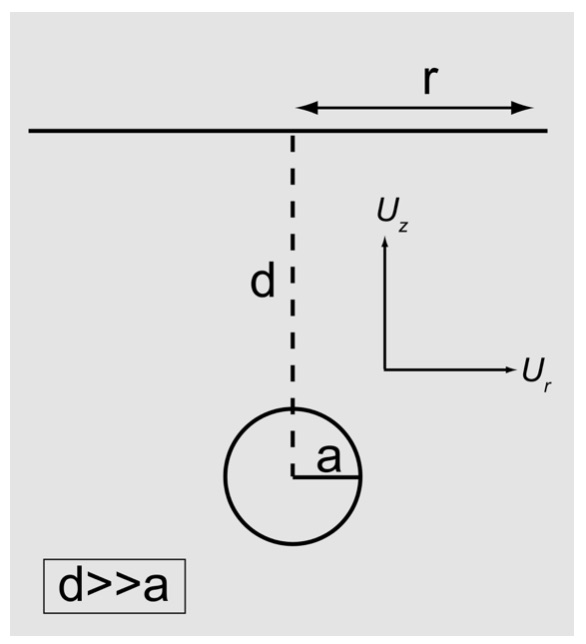

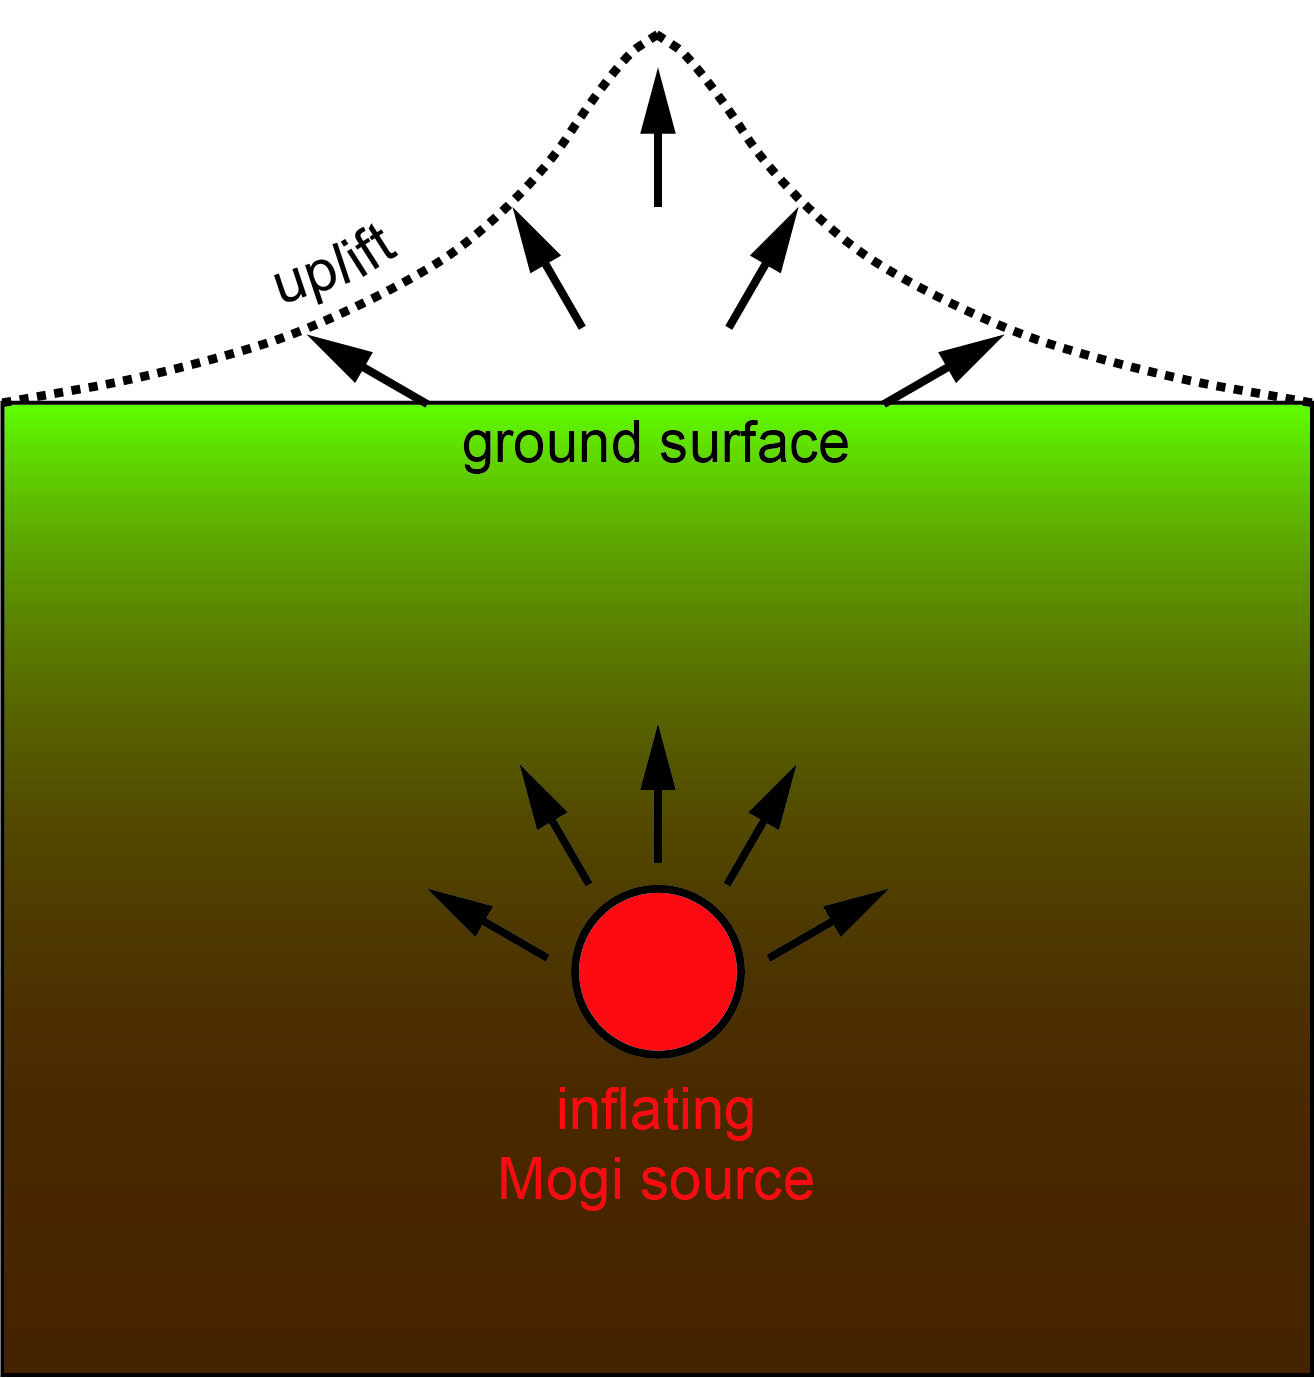

Inflating Mogi point-source causing vertical and horizontal displacement (USGS).


The relationship between surface displacements and pressure/volume change for a spherical source in an elastic half-space from Mogi (1958) is shown by the following equations, where $a$ is the magma chamber radius (500-1000 m), $∆P$ is pressure change in the chamber (10-40 MPa), $∆V$ is volume change (1 m^3-15 km^3), $G$ is the elastic shear modulus or rigidity (30 GPa or 3x10^10 Pa), $d$ is the depth to the center of the magma chamber (3-10 km), and $r$ is the radial distance from the point source (0-50 km).

**Pressure-change formulas:**

$$U_z = \frac{3\,a^{3}\,\Delta P\,d}{4\,G\,(d^{2}+r^{2})^{1.5}}
\qquad
U_r = \frac{3\,a^{3}\,\Delta P\,r}{4\,G\,(d^{2}+r^{2})^{1.5}}$$

**Volume-change formulas:**

$$U_z = \frac{3\,\Delta V\,d}{4\pi\,(d^{2}+r^{2})^{1.5}}
\qquad
U_r = \frac{3\,\Delta V\,r}{4\pi\,(d^{2}+r^{2})^{1.5}}$$

| Symbol | Meaning | Unit |
|---|---|---|
| $U_z$ | vertical (uplift positive) surface displacement | m |
| $U_r$ | horizontal (radial outward positive) displacement | m |
| $a$ | magma chamber radius (500 to 1000 m) | m |
| $\Delta P$ | pressure change in chamber (10 to 40 MPa) | Pa |
| $G$ | elastic shear modulus (30 GPa) | Pa |
| $d$ | depth to center of magma chamber (3 to 10 km) | m |
| $r$ | horizontal (radial) distance from volcano center | m |
| $\Delta V$ | volume change (1m³ to 15 km³)| m³ |

## Step 1: Define the Mogi Functions

This cell encodes the two Mogi model formulas (pressure and volume) as Python functions.
`mogi_pressure` takes the radial distance, depth, **pressure change**, chamber radius, and shear
modulus and returns the vertical and horizontal displacements. `mogi_volume` takes the radial distance, depth, **volume change**, chamber radius, and shear modulus and returns the vertical and horizontal displacements.. Defining these functions allows us to reuse these equations later on without having to rewrite them.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Mogi model: PRESSURE change
def mogi_pressure(radial_distance, depth, pressure_change, chamber_radius,
                  shear_modulus=30e9):
    """
    radial_distance : horizontal distance from volcano center,  r (m)
    depth           : depth to center of magma chamber,         d (m)
    pressure_change : pressure change in the chamber,           ΔP (Pa)
    chamber_radius  : magma chamber radius,                     a (m)
    shear_modulus   : elastic shear modulus,                    G (Pa) - default 30 GPa
    Returns (uplift, horizontal) surface displacement in meters.

    Formulas:
        Uz = 3 * a^3 * ΔP * d / [ 4 * G * (d^2 + r^2)^1.5 ]
        Ur = 3 * a^3 * ΔP * r / [ 4 * G * (d^2 + r^2)^1.5 ]
    """
    uplift     = (3 * chamber_radius**3 * pressure_change * depth) / \
                 (4 * shear_modulus * (depth**2 + radial_distance**2)**1.5)
    horizontal = (3 * chamber_radius**3 * pressure_change * radial_distance) / \
                 (4 * shear_modulus * (depth**2 + radial_distance**2)**1.5)
    
    return uplift, horizontal #OUTPUTS: vertical and horizontal displacements
    

# Mogi model: VOLUME change
def mogi_volume(radial_distance, depth, volume_change):
    """
    radial_distance : horizontal distance from volcano center, r (m)
    depth           : depth to center of magma chamber,        d (m)
    volume_change   : magma volume change, ΔV (m^3),  ΔV = π * a^3 * ΔP / G
    Returns (uplift, horizontal) surface displacement in meters.

    Formulas:
        Uz = 3 * ΔV * d / [ 4π * (d^2 + r^2)^1.5 ]
        Ur = 3 * ΔV * r / [ 4π * (d^2 + r^2)^1.5 ]
    """
    uplift     = (3 * volume_change * depth) / \
                 (4 * np.pi * (depth**2 + radial_distance**2)**1.5)
    horizontal = (3 * volume_change * radial_distance) / \
                 (4 * np.pi * (depth**2 + radial_distance**2)**1.5)
    
    return uplift, horizontal #OUTPUTS: vertical and horizontal displacements

print("Mogi functions defined.")

Mogi functions defined.


## Step 2: Load the Given Data

You have been given the below fixed values as function parameters. Run the following cell to store these given parameters as reusable variables. You will calculate deformation values for radial distances ranging from 0.5-30km. Pay special attention to the unit conversions taking place here.

- Shear Modulus ($G$) = 30 GPa
- Magma Chamber Radius ($a$) = 0.5 km
- Chamber Depth ($d$) = 5 km
- Change in Pressure ($\Delta P$) = 10 MPa


In [4]:
# Save given parameters
G  = 30e9      # shear modulus (Pa)        = 30 GPa
a  = 500.0     # magma chamber radius (m)  = 0.5 km
d  = 5000.0    # depth of chamber (m)      = 5 km
dP = 10e6      # pressure change (Pa)      = 10 MPa

# Fixed list of radial distances (km) to solve for
radial_km = [0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7,
             7.5, 8, 8.5, 9, 9.5, 10, 11, 12, 13, 14, 15, 20, 25, 30]

## Step 3: Apply the Mogi Pressure Formula to the Given Data

Using the provided information, we will now calculate vertical and horizontal displacement values at each radial distance. For this calculation, we will use the previoulsy defined Mogi pressure formulas. All values will be saved and presented in a Dataframe.

1. Apply the Mogi pressure formula at each radial distance value and create a Dataframe containing vertical and horizontal displacement calculations.

In [5]:
# Apply the Mogi pressure formula at each radial distance

pressure_rows = [] #placeholder for incoming values

#iterate through the list of radial distances, and apply both vertical and horizontal calculations at each distance
for r_km in radial_km:
    vertical, horizontal = mogi_pressure(r_km * 1000, d, dP, a, G) #save resulting displacement values as 'vertical' and 'horizontal'
    pressure_rows.append({"Radial Distance (km)": r_km, #add values to the dataset
                          "Vertical (m)": vertical,
                          "Horizontal (m)": horizontal})
    
#create a dataframe from the above list of calculated data points
df_pressure = pd.DataFrame(pressure_rows)
df_pressure

,Radial Distance (km),Vertical (m),Horizontal (m)
0,0.0,0.001250,0.000000
1,0.5,0.001231,0.000123
2,1.0,0.001179,0.000236
3,1.5,0.001098,0.000330
4,2.0,0.001001,0.000400
5,2.5,0.000894,0.000447
6,3.0,0.000788,0.000473
7,3.5,0.000687,0.000481
8,4.0,0.000595,0.000476
9,4.5,0.000513,0.000462


2. Now, plot the displacement values against radial distance to visualize the data.

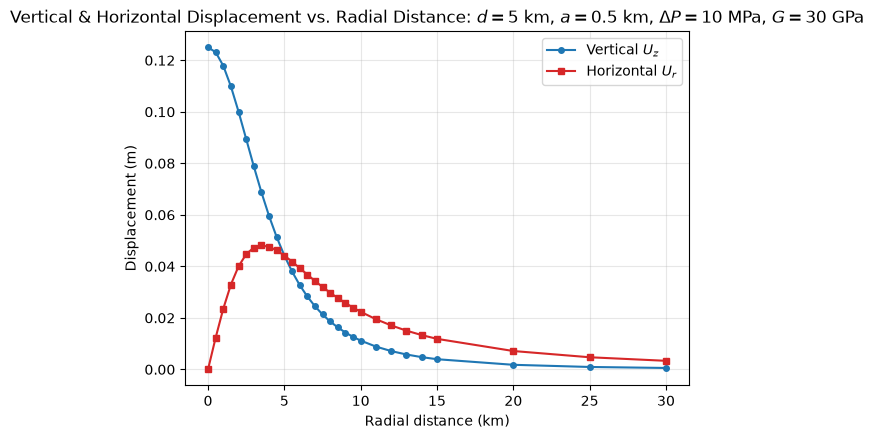

In [6]:
# Create a plot from the above dataframe
fig, ax = plt.subplots(figsize=(6.5, 4.6))

#select columns from the 'df_pressure' dataframe to plot on your x and y axes
ax.plot(df_pressure["Radial Distance (km)"], df_pressure["Vertical (m)"] * 100,        #vertical values
        "-o", color="#1f77b4", ms=4, label=r"Vertical $U_z$")

ax.plot(df_pressure["Radial Distance (km)"], df_pressure["Horizontal (m)"] * 100,      #horizontal values
        "-s", color="#d62728", ms=4, label=r"Horizontal $U_r$")

ax.set_title(r"Vertical & Horizontal Displacement vs. Radial Distance: $d=5$ km, $a=0.5$ km, $\Delta P=10$ MPa, $G=30$ GPa")
ax.set_xlabel("Radial distance (km)"); ax.set_ylabel("Displacement (m)")
ax.legend(); ax.grid(True, alpha=0.3)

### Pause and Compare: ###

What do you notice about the displacement trends for vertical vs. horizontal values? Add your answer to this markdown cell. Double click the cell to begin editing, and run the cell when finished to save your work.

## Step 4: Estimate Chamber Depth & Pressure using Displacement Data

This cell loads the observed displacement data of a volcano, "Volcano X."  The data used here were gathered by volcanologists prior to the 2010 eruption of Volcano X. Instead of using the Mogi equations to solve for displacement data (as we did previously), you will use the displacement data to estimate inputs to the equation. In this case, we will estimate chamber depth and pressure, holding the shear modulus and chamber radius values constant (30GPa and 1km, respectively).

In the first cell, you will load the newly given displacement data and define the fixed parameters. Then, you will plot the given values along with adjustable models for each set of values. Use the sliders to manipulate chamber depth and pressure values to approximate the given displacement data with the model.

1. Load the given displacement data from Volcano X and define the fixed parameters.

In [47]:
#Load new given data values

# Fixed parameters for Volcano X
a_fixed = 1000.0   # chamber radius (m) = 1km
G_fixed = 30e9     # shear modulus (Pa) = 30 GPa

#list of radial distance values in km
r_obs_km = np.array([0.56, 0.65, 0.90, 1.20, 1.56, 2.50, 2.75, 3.15, 3.76, 4.23,
                     5.00, 5.35, 5.98, 6.26, 6.87, 7.14, 7.79, 8.12, 9.35, 9.50,
                     10.20, 11.20, 12.50, 14.70, 15.20, 15.70, 19.78, 25.40, 32.00])

r_obs = r_obs_km * 1000.0   # convert radial distance values to meters for calculation

# Volcano X observed displacements ------------------------------

#list of vertical displacement values corresponding to each radial distance
Uz_obs = np.array([0.01568, 0.01563, 0.01547, 0.01521, 0.01482, 0.01347, 0.01305,
                   0.01235, 0.01125, 0.01040, 0.00905, 0.00847, 0.00750, 0.00709,
                   0.00628, 0.00595, 0.00522, 0.00489, 0.00383, 0.00372, 0.00324,
                   0.00269, 0.00212, 0.00146, 0.00135, 0.00125, 0.00069, 0.00035,
                   0.00018])  # m, vertical

#list of horizontal displacement values corresponding to each radial distance
Ur_obs = np.array([0.00118, 0.00136, 0.00187, 0.00245, 0.00310, 0.00452, 0.00482,
                   0.00522, 0.00568, 0.00590, 0.00607, 0.00608, 0.00602, 0.00596,
                   0.00579, 0.00570, 0.00546, 0.00532, 0.00480, 0.00474, 0.00444,
                   0.00404, 0.00356, 0.00288, 0.00275, 0.00263, 0.00184, 0.00120,
                   0.00079])  # m, horizontal


# Colour convention used throughout: vertical U_z in blue, horizontal U_r in red.
# Observed data are shown as symbols; model curves (later steps) as lines.
C_VERT, C_HORIZ = "#1f77b4", "#d62728"

2. Plot the given values along with adjustable models for each set of values. Use the sliders to manipulate chamber depth and pressure values to approximate the given displacement data with the model. If you receive an error when trying to display the slider "widgets," refresh your browser, and re-run this cell.

In [50]:
#Plot given data along with adjustable model

#import necessary packages to create adjustable sliders
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider

#define a function to plot the observed data and model together (model defaults to 5km chamber depth and 20MPa pressure change)
def plot_given_vs_model(depth_km=5.0, dP_MPa=20.0):
    # model prediction at the slider values
    Uz_model, Ur_model = mogi_pressure(r_obs, depth_km * 1000, dP_MPa * 1e6, a_fixed, G_fixed)

    fig, ax = plt.subplots(figsize=(9, 5.5))
    # given data (symbols)
    ax.plot(r_obs_km, Uz_obs * 100, "o", color=C_VERT, markeredgecolor="black",
            markersize=7, label="Given $U_z$ (vertical)")
    ax.plot(r_obs_km, Ur_obs * 100, "s", color=C_HORIZ, markeredgecolor="black",
            markersize=7, label="Given $U_r$ (horizontal)")
    # model (lines, same colours)
    ax.plot(r_obs_km, Uz_model * 100, "-", color=C_VERT,  lw=2, label="Model $U_z$")
    ax.plot(r_obs_km, Ur_model * 100, "-", color=C_HORIZ, lw=2, label="Model $U_r$")

    ax.set_xlabel("Radial distance (km)")
    ax.set_ylabel("Displacement (cm)")
    ax.set_title(f"Volcano X: given (symbols) vs model (lines)   "
                 f"d = {depth_km:.1f} km,  ΔP = {dP_MPa:.0f} MPa")
    ax.set_ylim(0, max(Uz_obs.max(), Ur_obs.max()) * 100 * 1.6)
    ax.legend(loc="upper right"); ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

#generate plot
interact(plot_given_vs_model,
         depth_km=FloatSlider(min=3.0, max=10.0, step=0.5, value=5.0,
                              description="Depth (km)", continuous_update=False),
         dP_MPa=FloatSlider(min=10.0, max=40.0, step=1.0, value=20.0,
                            description="ΔP (MPa)", continuous_update=False))

interactive(children=(FloatSlider(value=5.0, continuous_update=False, description='Depth (km)', max=10.0, min=…

<function __main__.plot_given_vs_model(depth_km=5.0, dP_MPa=20.0)>

### Pause and Answer: ###

At which chamber depth and pressure change values does your model best approximate the given data? How did increasing/decreasing each value affect the model? Do you think one parameter has a larger effect on the shape of the curve? Enter your answers in this markdown cell.

## Step 5: Conduct Pearson's $\chi^2$ Goodness of Fit Test on the Model

Now we will measure how closely the model reproduces the observations with Pearson's $\chi^2$
statistic. For each radial distance value, we take the squared mismatch between the displacement observation $O_i$ and the
model prediction $E_i$, normalize by $E_i$, and sum over all radial distance values:

$$\chi^2 = \sum_i \frac{(O_i - E_i)^2}{E_i}$$

A smaller $\chi^2$ means a better fit, where ($\chi^2 = 0$ is a perfect match). The best-fit
parameters are the ones that minimize the total $\chi^2$, summed over both the vertical and the
horizontal displacements.

| Symbol | Meaning |
|---|---|
| $O_i$ | observed displacement at radial distance $i$ |
| $E_i$ | model-predicted displacement at radial distance $i$ | 

1) First, we will define a function to compute the $\chi^2$ test based on model inputs

In [51]:
# function to compute chi-square values based on function parameters
def total_chi2(chamber_depth, pressure_change, a_m=a_fixed, G_Pa=G_fixed):
    """Pearson chi-square (expected in denominator), vertical + horizontal."""
    Ez, Er = mogi_pressure(r_obs, chamber_depth, pressure_change, a_m, G_Pa)
    chi2_v = np.sum((Uz_obs - Ez)**2 / Ez)
    chi2_h = np.sum((Ur_obs - Er)**2 / Er)
    return chi2_v + chi2_h, chi2_v, chi2_h

2) Next, you will define your best-fit parameters from Step 4 and run the computation. You may want to test multiple parameters here to try and lower your $\chi^2$ value.

In [52]:
chamber_depth = 5 #REPLACE YOUR CHOSEN CHAMBER DEPTH IN KM HERE
pressure_change = 20 #REPLACE YOUR CHOSEN PRESSURE CHANGE IN MPa HERE

# Compute chi-square using adjusted chamber depth and pressure value from the sliders
tot, cv, ch = total_chi2(chamber_depth*1000, pressure_change*1e6)
print(f"d={chamber_depth} km, dP={pressure_change} MPa  ->  chi2_vert={cv:.5f}, chi2_horiz={ch:.5f}, total_chi2={tot:.5f}")

d=5 km, dP=20 MPa  ->  chi2_vert=0.02240, chi2_horiz=0.01111, total_chi2=0.03352


### Pause and Answer: ### 

Did you adjust your best-fit parameters after computing the $\chi^2$ value? If so, what are the new best-fit parameters you found? Enter your answer in this markdown cell.

## Step 6: Grid Search for Best-Fit Parameters

We will now automate the process of finding best-fit parameters by completing a two-dimensional grid search over chamber depth (4 to 8 km) and $\Delta P$ (20 to 40 MPa), with radius and shear modulus held fixed. It records $\chi^2$ at every grid point, keeps the
minimum, and converts the best-fit $\Delta P$ to an equivalent volume change.

1. First, run the search over a two-dimensional grid.

In [53]:
#run the two-dimensional search

depths_search = np.arange(4000, 8001, 250)     # m
dP_search     = np.arange(20e6, 40.01e6, 1e6)  # Pa

chi2_grid = np.zeros((len(depths_search), len(dP_search)))
best_chi2, best_d, best_dP = np.inf, None, None
for i, d_try in enumerate(depths_search):
    for j, dP_try in enumerate(dP_search):
        c, _, _ = total_chi2(d_try, dP_try)
        chi2_grid[i, j] = c
        if c < best_chi2:
            best_chi2, best_d, best_dP = c, d_try, dP_try

print(f"Best-fit depth : {best_d/1000:.2f} km")
print(f"Best-fit dP    : {best_dP/1e6:.1f} MPa")
print(f"Minimum chi2   : {best_chi2:.3e}")

# Equivalent volume change
dV_best = np.pi * a_fixed**3 * best_dP / G_fixed
print(f"Equivalent volume change dV = pi*a^3*dP/G = {dV_best:.3e} m^3 = {dV_best/1e9:.5f} km^3")

Best-fit depth : 7.50 km
Best-fit dP    : 35.0 MPa
Minimum chi2   : 5.977e-05
Equivalent volume change dV = pi*a^3*dP/G = 3.665e+06 m^3 = 0.00367 km^3


2. Then, run this cell to draw the $\chi^2$ surface over the chamber depth and $\Delta P$ grid as a filled contour plot
(log scale) and mark the best-fit point.


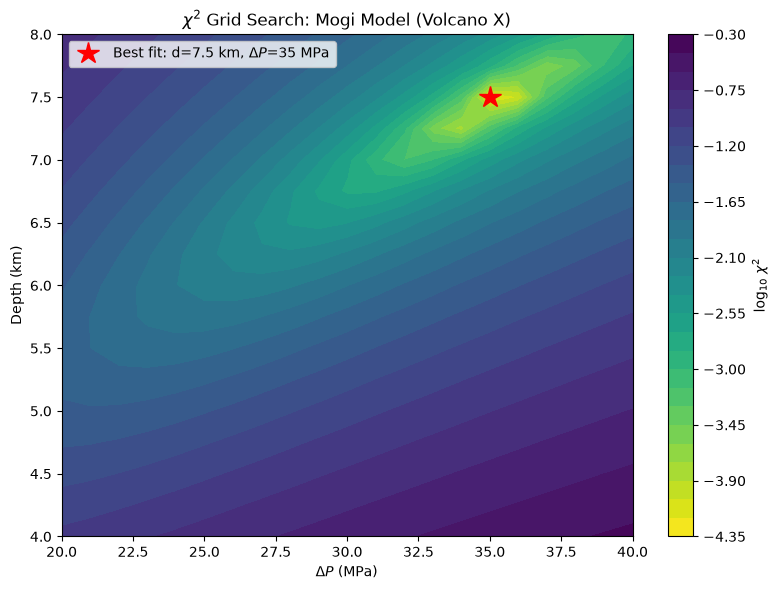

In [54]:
#plot the chi-square values
fig, ax = plt.subplots(figsize=(8, 6))
cp = ax.contourf(dP_search/1e6, depths_search/1000, np.log10(chi2_grid),
                 levels=25, cmap="viridis_r")
plt.colorbar(cp, ax=ax, label=r"$\log_{10}\,\chi^2$")
ax.plot(best_dP/1e6, best_d/1000, "r*", markersize=16,
        label=f"Best fit: d={best_d/1000:.1f} km, $\\Delta P$={best_dP/1e6:.0f} MPa")
ax.set_xlabel(r"$\Delta P$ (MPa)"); ax.set_ylabel("Depth (km)")
ax.set_title(r"$\chi^2$ Grid Search: Mogi Model (Volcano X)")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

3. Finally, plot the new best-fit model against our observed data.

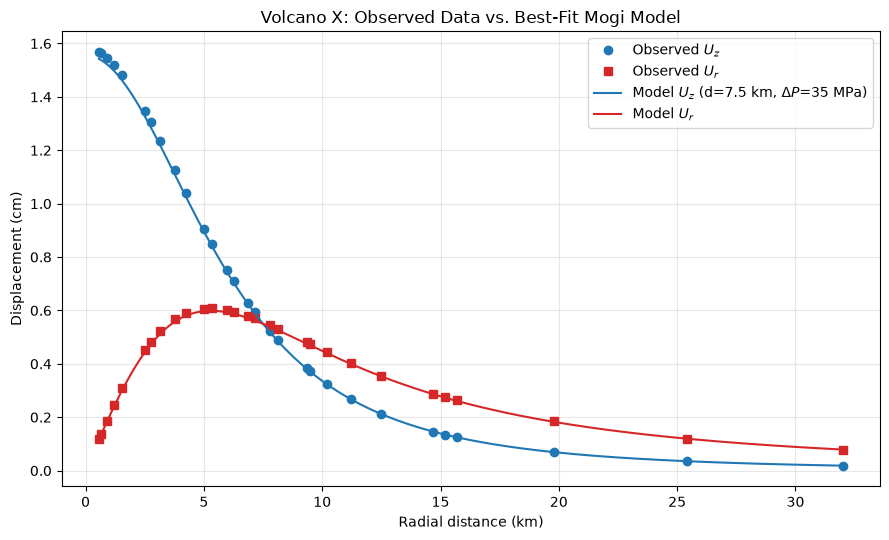

In [55]:
#Plot the newly calculated best-fit model along with observed displacement observations
rr = np.linspace(r_obs.min(), r_obs.max(), 300)
Ez_fit, Er_fit = mogi_pressure(rr, best_d, best_dP, a_fixed)

# Same convention: vertical U_z in blue, horizontal U_r in red;
# observed = symbols, best-fit model = lines of the same colour.
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(r_obs_km, Uz_obs*100, "o", color=C_VERT,  label="Observed $U_z$")
ax.plot(r_obs_km, Ur_obs*100, "s", color=C_HORIZ, label="Observed $U_r$")
ax.plot(rr/1000, Ez_fit*100, "-", color=C_VERT,
        label=f"Model $U_z$ (d={best_d/1000:.1f} km, $\\Delta P$={best_dP/1e6:.0f} MPa)")
ax.plot(rr/1000, Er_fit*100, "-", color=C_HORIZ, label="Model $U_r$")
ax.set_xlabel("Radial distance (km)"); ax.set_ylabel("Displacement (cm)")
ax.set_title("Volcano X: Observed Data vs. Best-Fit Mogi Model")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### Pause and Compare: ###

How does the minimum $\chi^2$ value found by the grid search compare to the value you calculated earlier? What insights can be gathered from automating and visualizing a best-fit test for our model?

## Assignment: Applying the Volume Change Formula

1. Calculate and plot horizontal and vertical displacement values given a chamber depth of 5 km and a volume change of 1 km^3. Note that the volume change formula has already been defined for you in Step 1. You should follow a similar process as you have done for pressure change in Steps 1-3, computing displacement across a range of radial distance values.
2. Calculate and show plots for the best-fit parameters (i.e., minimum χ2 for change in volume and depth) that fit the displacement data for Volcano X.  (Assume radius = 1 km and shear modulus = 30 GPa are held constant!).  Use a range of ∆V from 0.5 to 5 km^3. Hint: Use Steps 4-6 to your advantage!
3. Answer: Is there a difference between the estimated chamber depths when applying the pressure vs. volume change formula?  What may cause this difference?


Use the plus button at the top of the screen to add additional code and markdown cells as needed.